In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
sys.path.append("..")
from utils.funcion import construir_temporada
players = pd.read_csv("/Users/pma/Bootcamp/EDA-futbol/src/data/players.csv")
valuations = pd.read_csv("/Users/pma/Bootcamp/EDA-futbol/src/data/player_valuations.csv")
appearances = pd.read_csv("/Users/pma/Bootcamp/EDA-futbol/src/data/appearances.csv")

In [3]:
# Fechas

players["date_of_birth"] = pd.to_datetime(players["date_of_birth"])
valuations["date"] = pd.to_datetime(valuations["date"])
appearances["date"] = pd.to_datetime(appearances["date"])
# datetime para pasar de str a datetime64ns(objeto temporal de Pandas)

In [4]:
temporadas = [("2023-07-01", "2024-06-30"), ("2024-07-01", "2025-06-30"), ("2025-07-01", "2026-06-30")] # Establezco las temporadas a usar.

dfs = [construir_temporada(players, valuations, appearances, inicio, fin) for inicio, fin in temporadas] # Con un bucle for recorro todas las temporadas elegidas.
df_total = pd.concat(dfs, ignore_index=True) # Concateno los DF.

print(df_total.shape)
print(df_total["temporada"].value_counts())


(2579, 11)
temporada
2025/2026    881
2023/2024    873
2024/2025    825
Name: count, dtype: int64


In [5]:
print((df_total["edad"] < 23).sum()) # Esto cuenta True como 1 y False como 0 asi que me daria el total de jugadores que cumplen la condicion. 
print(df_total[df_total["edad"] < 23].groupby("temporada").size()) # Agrupo por los jugadores de menos de 23 por temporada. 
# DATO: un mismo jugador puede estar en las 3 temporadas. 

455
temporada
2023/2024    159
2024/2025    145
2025/2026    151
dtype: int64


In [6]:
df_total.to_csv("/Users/pma/Bootcamp/EDA-futbol/src/data/dataset_3_temporadas.csv", index=False) # Guardo el dataset ya filtrado asi no tenga que cargar todo de nuevo.(Por si acaso) 

In [7]:
df_total["tramo_edad"] = pd.cut(df_total["edad"], bins=[0, 23, 28, 100], labels=["menos de 23", "23 a 27", "28 o más"], right=False) # cut crea una columna nueva "tramo_edad"
# que dice EN CUAL de los 3 grupos cae cada jugador, bins separa por tramos, labels es el nombre de cada tramo y right decide que el limite derecho queda afuera.

print(df_total.groupby("tramo_edad", observed=True).size())
print(df_total.groupby("tramo_edad", observed=True)[["market_value_in_eur", "ga_90"]].median())

tramo_edad
menos de 23     455
23 a 27        1174
28 o más        949
dtype: int64
             market_value_in_eur     ga_90
tramo_edad                                
menos de 23           18000000.0  0.275651
23 a 27               15000000.0  0.323510
28 o más               5000000.0  0.297030


In [8]:
# Resultado: NO SE CONFIRMA.
# - 455 jugadores-temporada con menos de 23 años (sobre 2.579 en total).
# - Correlación del log del valor con ga_90: 0,49 (moderada, positiva).
# - Correlación del log del valor con la edad: -0,20 (débil, negativa).
# - Dentro de este grupo, el valor se asocia más con el rendimiento que con la edad.
#
# Cuidados: entre 17 y 23 años la edad varía poco, así que tiene poco margen
# para mostrar efecto. Una correlación no prueba causa, y el valor de
# Transfermarkt ya tiene en cuenta cómo juega el futbolista.
# ---------------------------------------------------------------

print(df_total["edad"].isna().sum()) # Sumo los datos que son NaN

jovenes = df_total[df_total["edad"] < 23].copy() # trabajo sobre una copia de la tabla(df_total)
jovenes["log_valor"] = np.log10(jovenes["market_value_in_eur"]) # uso log10 para determinar cuantas veces vale mas un jugador que otro(no por KK)
print(jovenes[["log_valor", "edad", "ga_90"]].corr()) # corr sirve para hacer una correlacion, entre las columnas, en un DF que va de -1 a 1 donde 1 es una correlacion perfecta. 

# Resultado: H1 se asocia mas con el rendimiento (ga_90) que con la edad por ende H1 no se estaria cumpliendo. 

1
           log_valor      edad     ga_90
log_valor   1.000000 -0.196024  0.487023
edad       -0.196024  1.000000 -0.042137
ga_90       0.487023 -0.042137  1.000000


In [9]:
# H2: Pasados los 28 años, el valor cae aunque el rendimiento se mantenga.
#
# Resultado: SE SOSTIENE, con matices.
# - Valor mediano: de 15 M (23 a 27 años) a 5 M (28 o más), una caída de ~67%.
# - ga_90 mediano: de 0,32 a 0,30, una caída de ~8%.
# - Correlación del log del valor con la edad: -0,11 (23 a 27) y -0,48 (28 o más).
# - Correlación del log del valor con ga_90: 0,43 en los de 28 o más.
# - Pasados los 28, la edad pasa a asociarse con el valor tanto como el
#   rendimiento, cosa que no ocurre antes. El rendimiento sigue importando.
#
# Cuidados: el rango de edad es mucho más amplio en el tramo de 28 o más.
# Además, los veteranos con 900 minutos o más son los que siguen siendo buenos,
# así que su rendimiento sale algo inflado.
# ---------------------------------------------------------------

for tramo in ["23 a 27", "28 o más"]: # Para recorrer los dos tramos que me faltan de los jugadores.
    sub = df_total[df_total["tramo_edad"] == tramo].copy() # Utilizo una copia del DF para no utilizar el original.
    sub["log_valor"] = np.log10(sub["market_value_in_eur"]) # Lo mismo que hice antes solo que cambiando los datos de los jugadores.
    print(tramo)
    print(sub[["log_valor", "edad", "ga_90"]].corr()["log_valor"]) # Misma linea que antes para determinar la correlacion. 

23 a 27
log_valor    1.000000
edad        -0.107630
ga_90        0.451838
Name: log_valor, dtype: float64
28 o más
log_valor    1.000000
edad        -0.475971
ga_90        0.425941
Name: log_valor, dtype: float64


In [10]:
# ---------------------------------------------------------------
# H3 (parte A): El rendimiento ofensivo explica el valor de forma distinta
#               según la posición.
#
# Resultado: SE SOSTIENE, con matices.
# - Atacante(Attack) (1.166 jugadores-temporada): ga_90 = 0,51; edad = -0,46.
# - Mediocampista(Midfield) (1.413): ga_90 = 0,37; edad = -0,48.
# - En los delanteros el rendimiento pesa algo más que la edad; en los
#   mediocampistas, la edad pesa más que el rendimiento.
#
# Cuidados: ga_90 solo mide goles y asistencias, y subestima el aporte de los
# mediocampistas. No se analiza la liga porque df_total no la incluye.

df_total["log_valor"] = np.log10(df_total["market_value_in_eur"])

for pos in ["Attack", "Midfield"]: # uso el for para que recorra por atacante y mediocampista.
    sub = df_total[df_total["position"] == pos]
    print(pos, len(sub))
    print(sub[["log_valor", "edad", "ga_90"]].corr()["log_valor"]) # imprimo dos cosas, primero la posicion y despues la correlacion que hay entre posicion, valor, edad y ga_90

Attack 1166
log_valor    1.000000
edad        -0.460535
ga_90        0.506170
Name: log_valor, dtype: float64
Midfield 1413
log_valor    1.000000
edad        -0.482341
ga_90        0.373535
Name: log_valor, dtype: float64


In [11]:
# H3 (parte B)que jugador costaria mucho mas(o mucho menos) de lo que su ga_90 sugiere.

col_nombre = "name"

actual = df_total[df_total["temporada"] == "2025/2026"].copy()

actual["pct_valor"] = actual.groupby("position")["market_value_in_eur"].rank(pct=True)
actual["pct_rend"] = actual.groupby("position")["ga_90"].rank(pct=True)
actual["desajuste"] = actual["pct_valor"] - actual["pct_rend"]

cols = [col_nombre, "position", "edad", "market_value_in_eur", "ga_90", "desajuste", "pct_valor", "pct_rend"]

In [12]:
# H3 (parte B) -> muestro los 5 casos mas extremos de cada lado, con el valor formateado con puntos para que sea mas facil de leer. 
def formato(df):
    t = df[cols].copy()
    t["market_value_in_eur"] = t["market_value_in_eur"].apply(lambda x: f"{x:,.0f}".replace(",", "."))
    t["edad"] = t["edad"].round(1) # edad se calculo dividiendo sobre 365.25 por eso redondeo a 1 decimal.
    t["ga_90"] = t["ga_90"].round(2) # Redondeo para una mejor "presentacion"
    t["desajuste"] = t["desajuste"].round(2)
    return t

print("Valor muy por encima de su rendimiento:")
print(formato(actual.sort_values("desajuste", ascending=False).head(5)))

print("Valor muy por debajo de su rendimiento:")
print(formato(actual.sort_values("desajuste").head(5)))

Valor muy por encima de su rendimiento:
                     name  position  edad market_value_in_eur  ga_90  \
2535        Carlos Baleba  Midfield  22.5          55.000.000   0.00   
2066  Aurélien Tchouaméni  Midfield  26.4          70.000.000   0.03   
2553   Franco Mastantuono    Attack  18.9          45.000.000   0.09   
2563       Ayyoub Bouaddi  Midfield  18.7          50.000.000   0.04   
2268       Anthony Elanga    Attack  24.2          32.000.000   0.07   

      desajuste  pct_valor  pct_rend  
2535       0.90   0.929325  0.027426  
2066       0.87   0.947257  0.073840  
2553       0.87   0.889435  0.023342  
2563       0.84   0.916667  0.078059  
2268       0.79   0.793612  0.004914  
Valor muy por debajo de su rendimiento:
                     name  position  edad market_value_in_eur  ga_90  \
1735  Michael Gregoritsch    Attack  32.2           1.500.000   0.88   
1698        Jonas Hofmann  Midfield  34.0           1.500.000   0.45   
1819       Sofiane Boufal  Midfield  

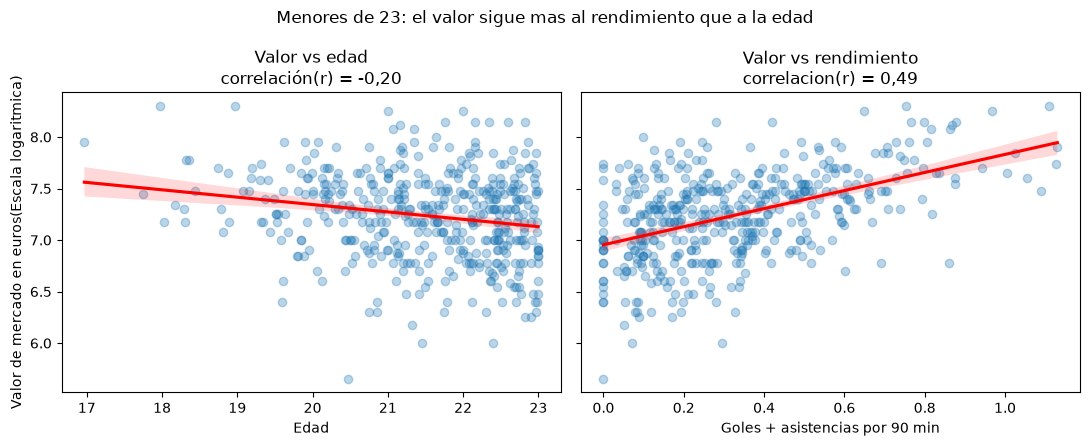

In [13]:
# Grafico H1. 

jovenes = df_total[df_total["edad"] < 23].copy()
jovenes["log_valor"] = np.log10(jovenes["market_value_in_eur"])

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

sns.regplot(data=jovenes, x="edad", y="log_valor", ax=ejes[0],
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
ejes[0].set_title("Valor vs edad\ncorrelación(r) = -0,20")
ejes[0].set_xlabel("Edad")
ejes[0].set_ylabel("Valor de mercado en euros(Escala logaritmica)")

sns.regplot(data=jovenes, x="ga_90", y="log_valor", ax=ejes[1],
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
ejes[1].set_title("Valor vs rendimiento\ncorrelacion(r) = 0,49")
ejes[1].set_xlabel("Goles + asistencias por 90 min")
ejes[1].set_ylabel("")

fig.suptitle("Menores de 23: el valor sigue mas al rendimiento que a la edad")
plt.tight_layout()
plt.savefig("../../presentacion/img/h1_jovenes.png", dpi=150, bbox_inches="tight")
plt.show()

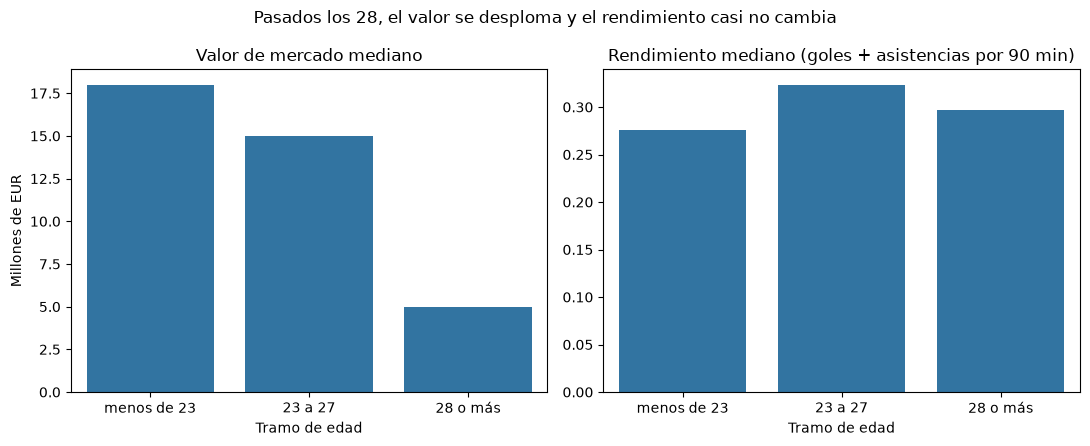

In [14]:
# Grafico H2

df_total["valor_M"] = df_total["market_value_in_eur"] / 1_000_000

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.barplot(data=df_total, x="tramo_edad", y="valor_M", estimator="median",
            errorbar=None, ax=ejes[0])
ejes[0].set_title("Valor de mercado mediano")
ejes[0].set_xlabel("Tramo de edad")
ejes[0].set_ylabel("Millones de EUR")

sns.barplot(data=df_total, x="tramo_edad", y="ga_90", estimator="median",
            errorbar=None, ax=ejes[1])
ejes[1].set_title("Rendimiento mediano (goles + asistencias por 90 min)")
ejes[1].set_xlabel("Tramo de edad")
ejes[1].set_ylabel("")

fig.suptitle("Pasados los 28, el valor se desploma y el rendimiento casi no cambia")
plt.tight_layout()

os.makedirs("../../presentacion/img", exist_ok=True)
plt.savefig("../../presentacion/img/h2_veteranos.png", dpi=150, bbox_inches="tight")
plt.show()

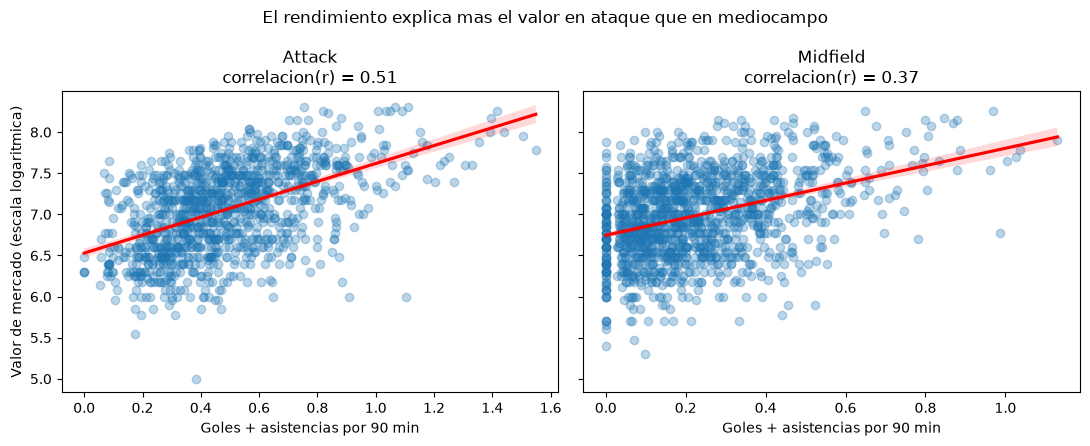

In [15]:
# Grafico H3

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, pos in zip(ejes, ["Attack", "Midfield"]):
    sub = df_total[df_total["position"] == pos]
    r = sub["log_valor"].corr(sub["ga_90"])
    sns.regplot(data=sub, x="ga_90", y="log_valor", ax=ax,
                scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
    ax.set_title(f"{pos}\ncorrelacion(r) = {r:.2f}")
    ax.set_xlabel("Goles + asistencias por 90 min")
    ax.set_ylabel("Valor de mercado (escala logaritmica)" if pos == "Attack" else "")

fig.suptitle("El rendimiento explica mas el valor en ataque que en mediocampo")
plt.tight_layout()

os.makedirs("../../presentacion/img", exist_ok=True)
plt.savefig("../../presentacion/img/h3_posicion.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
#df_total[df_total["tramo_edad"].isna()] chequeo del jugador que no tiene fecha de nacimiento

,player_id,minutes_played,goals,assists,market_value_in_eur,name,date_of_birth,position,edad,ga_90,temporada,tramo_edad,log_valor,valor_M
7,31599,1258,0,1,300000,Norman Theuerkauf,NaT,Midfield,NaN,0.071542,2023/2024,NaN,5.477121,0.3
